# Kết quả đã chạy bằng script

Snapshot từ `results.csv`; các code cell phía trên để chạy lại, chưa đánh dấu là đã execute trong notebook.

| Model | Max_length | Accuracy | Precision | Recall | F1 | Training_time_s |
|---|---|---|---|---|---|---|
| TF-IDF + LR | full | 0.8489 | 0.8431 | 0.8581 | 0.8505 | 0.3884 |
| RNN | 100 | 0.5044 | 0.5045 | 0.6231 | 0.5575 | 3.9316 |
| LSTM | 100 | 0.5689 | 0.6068 | 0.3969 | 0.4799 | 4.0335 |
| GRU | 100 | 0.5922 | 0.6123 | 0.5078 | 0.5552 | 6.4522 |
| RNN | 50 | 0.4967 | 0.4983 | 0.6563 | 0.5665 | 2.2981 |
| RNN | 200 | 0.5833 | 0.5969 | 0.5188 | 0.5552 | 11.2762 |

Cấu hình và giới hạn: 6.000 review, 3 epochs, CPU. Dataset: `IMDB_Dataset.csv`; dùng conda `HUS_NLP`. Đây là kết quả thử nghiệm ngắn; chưa tuning.

Phần suy luận cá nhân: hoàn thành calculations.md, prediction.md, reflection.md và xác nhận từng nhận xét trong error_analysis.md.

# Setup

In [1]:
from pathlib import Path
import os
import re
import time
import random


In [2]:
import json
import platform
from collections import Counter
import numpy as np
import pandas as pd
from IPython.display import display


In [3]:
import matplotlib

%matplotlib inline
import matplotlib.pyplot as plt
import torch
from torch import nn


In [4]:
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer


In [5]:
from sklearn.linear_model import LogisticRegression
from rnn_cell import SimpleRNNCell

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
os.chdir(ROOT)
SEED = 67


In [6]:
EPOCHS = int(os.environ.get("LAB_EPOCHS", 3))
SAMPLES = int(os.environ.get("LAB_SAMPLES", 6000))  # 0: toàn bộ dữ liệu sạch
BATCH = 64
EMBED = HIDDEN = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [7]:
torch.set_num_threads(4)


In [8]:
def seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)


In [9]:
seed()
print("Device:", DEVICE, "| Python:", platform.python_version())


Device: cuda | Python: 3.10.21


# Experiment 1 — Dataset inspection

In [10]:
df = pd.read_csv(ROOT / "IMDB_Dataset.csv")
display(df.head())
dataset_summary = pd.DataFrame([{
    "Samples": len(df),
    "Classes": df.sentiment.nunique(),
    "Missing reviews": df.review.isna().sum(),
    "Missing labels": df.sentiment.isna().sum(),
    "Empty reviews": df.review.fillna("").str.strip().eq("").sum(),
    "Duplicate reviews": df.review.duplicated().sum(),
}])
display(dataset_summary)
class_distribution = df.sentiment.value_counts(dropna=False).rename_axis("Sentiment").reset_index(name="Samples")
class_distribution["Percentage (%)"] = 100 * class_distribution.Samples / len(df)
display(class_distribution.round(2))


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


,Samples,Classes,Missing reviews,Missing labels,Empty reviews,Duplicate reviews
0,50000,2,0,0,0,418


,Sentiment,Samples,Percentage (%)
0,positive,25000,50.0
1,negative,25000,50.0


In [11]:
# Thống kê toàn bộ dữ liệu gốc bằng whitespace tokenizer như notebook cũ.
raw_lengths = df.review.fillna("").str.split().str.len()
length_summary = raw_lengths.describe().rename_axis("Statistic").reset_index(name="Sequence length")
display(length_summary.round(2))
length_quantiles = raw_lengths.quantile([0.90, 0.95, 0.99]).rename_axis("Quantile").reset_index(name="Sequence length")
display(length_quantiles.round(2))


,Statistic,Sequence length
0,count,50000.00
1,mean,231.16
2,std,171.34
3,min,4.00
4,25%,126.00
5,50%,173.00
6,75%,280.00
7,max,2470.00


,Quantile,Sequence length
0,0.90,451.0
1,0.95,590.0
2,0.99,908.0


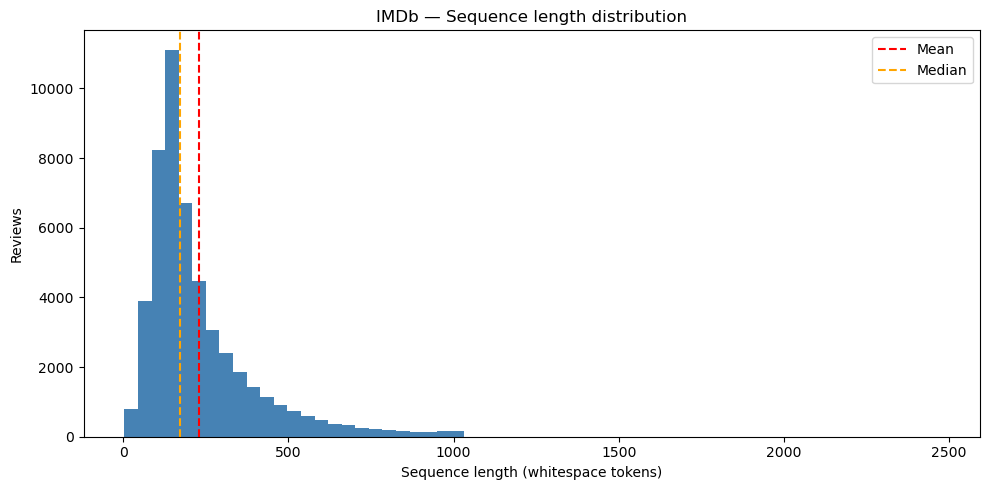

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(raw_lengths, bins=60, color="steelblue")
ax.axvline(raw_lengths.mean(), color="red", linestyle="--", label="Mean")
ax.axvline(raw_lengths.median(), color="orange", linestyle="--", label="Median")
ax.set_xlabel("Sequence length (whitespace tokens)")
ax.set_ylabel("Reviews")
ax.set_title("IMDb — Sequence length distribution")
ax.legend()
fig.tight_layout()
plt.show()


In [13]:
# Loại duplicate trước split để tránh leakage.
df = df.dropna(subset=["review", "sentiment"]).copy()
df = df[df.review.str.strip().ne("")].drop_duplicates("review")
df["label"] = df.sentiment.map({"negative": 0, "positive": 1})
assert df.label.notna().all()


In [14]:
if SAMPLES and SAMPLES < len(df):
    df, _ = train_test_split(
        df, train_size=SAMPLES, stratify=df.label, random_state=SEED
    )
train, holdout = train_test_split(
    df, test_size=0.3, stratify=df.label, random_state=SEED
)
val, test = train_test_split(
    holdout, test_size=0.5, stratify=holdout.label, random_state=SEED
)
split_summary = pd.DataFrame({"Split": ["Train", "Validation", "Test"], "Samples": [len(train), len(val), len(test)]})
display(split_summary)


,Split,Samples
0,Train,4200
1,Validation,900
2,Test,900


In [15]:
truncation_rows = []
for max_length in [128, 256, 512, 1024]:
    truncation_rows.append({
        "max_length": max_length,
        "Truncated Reviews (%)": (raw_lengths > max_length).mean() * 100,
        "Lost Tokens (%)": 100 * (raw_lengths - max_length).clip(lower=0).sum() / max(1, raw_lengths.sum()),
    })
truncation_df = pd.DataFrame(truncation_rows)
display(truncation_df.round(2))


,max_length,Truncated Reviews (%),Lost Tokens (%)
0,128,73.45,48.46
1,256,28.58,23.03
2,512,7.39,5.97
3,1024,0.08,0.12


Giá trị max_length nên được lựa chọn dựa trên phân phối độ dài chuỗi, tỷ lệ review bị truncation và tỷ lệ token bị mất. Theo kết quả thống kê, khi max_length = 1024, chỉ có 0.08% review bị cắt và 0.12% token bị mất. Điều này cho thấy giá trị 1024 có khả năng bảo toàn gần như toàn bộ nội dung của tập dữ liệu.

Tuy nhiên, vì RNN xử lý dữ liệu tuần tự theo từng bước thời gian, việc lựa chọn max_length lớn có thể làm tăng chi phí tính toán và gây khó khăn trong việc học các phụ thuộc dài hạn. Do đó em chọn max_length = 512 là lựa chọn hợp lý để cân bằng giữa hiệu quả tính toán và khả năng giữ lại thông tin.

# Tokenization, padding và truncation

In [16]:
def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|[0-9]+", text.lower())


In [17]:
counter = Counter(t for text in train.review for t in tokenize(text))
vocab = {"<PAD>": 0, "<UNK>": 1}
vocab.update(
    {w: i + 2 for i, (w, n) in enumerate(counter.most_common(19998)) if n >= 2}
)
# Đánh lại chỉ số để vocab liên tục.
vocab = {w: i for i, w in enumerate(vocab)}
print("Vocabulary:", len(vocab))


Vocabulary: 20000


In [18]:
def encode(text, length):
    ids = [vocab.get(t, 1) for t in tokenize(text)[:length]] or [1]
    return ids + [0] * (length - len(ids)), len(ids)


In [19]:
def loader(frame, length, shuffle=False):
    encoded = [encode(t, length) for t in frame.review]
    data = TensorDataset(
        torch.tensor([x[0] for x in encoded]),
        torch.tensor([x[1] for x in encoded]),
        torch.tensor(frame.label.to_numpy(), dtype=torch.float32),
    )
    return DataLoader(
        data,
        batch_size=BATCH,
        shuffle=shuffle,
        generator=torch.Generator().manual_seed(SEED),
    )


In [20]:
example_ids, example_length = encode("I really like this movie", 8)
display(pd.DataFrame([{"Text": "I really like this movie", "Token IDs (padded)": example_ids, "Length": example_length}]))
lengths = train.review.map(lambda t: len(tokenize(t)))
retained = {
    n: 100 * lengths.clip(upper=n).sum() / max(1, lengths.sum())
    for n in [30, 50, 100, 200, 512]
}
retained_df = pd.DataFrame(retained.items(), columns=["Max_length", "Tokens_retained_pct"])
display(retained_df.round(2))


,Text,Token IDs (padded),Length
0,I really like this movie,"[10, 66, 38, 12, 18, 0, 0, 0]",5


,Max_length,Tokens_retained_pct
0,30,12.78
1,50,21.22
2,100,41.14
3,200,68.60
4,512,94.14


# Core implementation — NumPy vs PyTorch

In [21]:
seed()
cell = SimpleRNNCell(2, 3)
x = np.array([1.0, 0.5])
h = np.array([0.1, 0.2, 0.3])
reference = nn.RNNCell(2, 3).double()


In [22]:
with torch.no_grad():
    reference.weight_ih.copy_(torch.from_numpy(cell.W_xh))
    reference.weight_hh.copy_(torch.from_numpy(cell.W_hh))
    reference.bias_ih.copy_(torch.from_numpy(cell.b_h))
    reference.bias_hh.zero_()


In [23]:
a = cell.forward(x, h)
b = reference(torch.from_numpy(x), torch.from_numpy(h)).detach().numpy()
np.testing.assert_allclose(a, b, atol=1e-12)
cell_comparison = pd.DataFrame({"NumPy": a, "PyTorch": b, "Absolute difference": np.abs(a - b)})
display(cell_comparison)


,NumPy,PyTorch,Absolute difference
0,0.842876,0.842876,0.0
1,-0.779355,-0.779355,0.0
2,-0.633171,-0.633171,0.0


# Model và training loop

In [24]:
class SentimentModel(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab), EMBED, padding_idx=0)
        self.recurrent = getattr(nn, kind)(EMBED, HIDDEN, batch_first=True)
        self.fc = nn.Linear(HIDDEN, 1)

    def forward(self, x, lengths):
        # Lấy output ở token thật cuối cùng, không lấy vị trí PAD.
        outputs, _ = self.recurrent(self.embedding(x))
        last = outputs[torch.arange(len(x), device=x.device), lengths.to(x.device) - 1]
        return self.fc(last).squeeze(1)


In [25]:
criterion = nn.BCEWithLogitsLoss()


In [26]:
def evaluate(model, data):
    model.eval()
    losses = 0.0
    probs = []
    labels = []
    with torch.no_grad():
        for x, l, y in data:
            logits = model(x.to(DEVICE), l)
            losses += criterion(logits, y.to(DEVICE)).item() * len(y)
            probs.extend(logits.sigmoid().cpu().tolist())
            labels.extend(y.tolist())
    return losses / len(data.dataset), np.array(probs), np.array(labels)


In [27]:
def metrics(y, p):
    pred = np.asarray(p) >= 0.5
    return dict(
        Accuracy=accuracy_score(y, pred),
        Precision=precision_score(y, pred, zero_division=0),
        Recall=recall_score(y, pred, zero_division=0),
        F1=f1_score(y, pred, zero_division=0),
    )


In [28]:
models = {}
histories = {}
rows = []


In [29]:
def fit(kind, length):
    seed()
    model = SentimentModel(kind).to(DEVICE)
    optim = torch.optim.Adam(model.parameters(), lr=0.001)
    tr = loader(train, length, True)
    va = loader(val, length)
    history = []
    best = float("inf")
    state = None
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        model.train()
        total = 0.0
        for x, l, y in tr:
            optim.zero_grad()
            loss = criterion(model(x.to(DEVICE), l), y.to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optim.step()
            total += loss.item() * len(y)
        vl, _, _ = evaluate(model, va)
        history.append(
            {
                "epoch": epoch + 1,
                "train_loss": total / len(train),
                "validation_loss": vl,
            }
        )
        if vl < best:
            best = vl
            state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(kind, length, history[-1], flush=True)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    model.load_state_dict(state)
    vl, _, _ = evaluate(model, va)
    _, probs, y = evaluate(model, loader(test, length))
    row = dict(
        Model=kind,
        Max_length=length,
        Parameters=sum(p.numel() for p in model.parameters()),
        Training_time_s=elapsed,
        Epochs=EPOCHS,
        Vocabulary=len(vocab),
        Tokens_retained_pct=retained[length],
        Validation_loss=vl,
        **metrics(y, probs),
        GPU_peak_MB=(
            torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == "cuda" else None
        )
    )
    rows.append(row)
    models[(kind, length)] = model
    histories[(kind, length)] = history
    pd.DataFrame(rows).to_csv("results.csv", index=False)
    return model


# Experiment 3 — TF-IDF + Logistic Regression

In [30]:
start = time.perf_counter()
baseline = make_pipeline(
    TfidfVectorizer(max_features=20000, ngram_range=(1, 1)),
    LogisticRegression(max_iter=1000, random_state=SEED),
)
baseline.fit(train.review, train.label)
elapsed = time.perf_counter() - start
bp = baseline.predict_proba(test.review)[:, 1]


In [31]:
rows.append(
    dict(
        Model="TF-IDF + LR",
        Max_length="full",
        Parameters=baseline[-1].coef_.size + 1,
        Training_time_s=elapsed,
        Epochs=None,
        Vocabulary=len(baseline[0].vocabulary_),
        Tokens_retained_pct=100,
        Validation_loss=None,
        **metrics(test.label, bp),
        GPU_peak_MB=None
    )
)
baseline_results = pd.DataFrame([rows[-1]])
display(baseline_results.round(4))


,Model,Max_length,Parameters,Training_time_s,Epochs,Vocabulary,Tokens_retained_pct,Validation_loss,Accuracy,Precision,Recall,F1,GPU_peak_MB
0,TF-IDF + LR,full,20001,0.4928,None,20000,100,None,0.8489,0.8431,0.8581,0.8505,None


# Experiment 4 — RNN vs LSTM vs GRU

In [32]:
for kind in ["RNN", "LSTM", "GRU"]:
    fit(kind, 100)


RNN 100 {'epoch': 1, 'train_loss': 0.699016052768344, 'validation_loss': 0.6930863587061564}
RNN 100 {'epoch': 2, 'train_loss': 0.682712048462459, 'validation_loss': 0.6936973020765517}
RNN 100 {'epoch': 3, 'train_loss': 0.6660663122222537, 'validation_loss': 0.696224897702535}
LSTM 100 {'epoch': 1, 'train_loss': 0.6943235314460028, 'validation_loss': 0.6917704770300124}
LSTM 100 {'epoch': 2, 'train_loss': 0.6825698942229861, 'validation_loss': 0.6860663554403517}
LSTM 100 {'epoch': 3, 'train_loss': 0.6546099953424362, 'validation_loss': 0.6565082404348586}
GRU 100 {'epoch': 1, 'train_loss': 0.6949273648716154, 'validation_loss': 0.6934625487857394}
GRU 100 {'epoch': 2, 'train_loss': 0.6788099791890099, 'validation_loss': 0.6873563390307956}
GRU 100 {'epoch': 3, 'train_loss': 0.6478667603220258, 'validation_loss': 0.6554175096087985}


In [33]:
architecture_results = pd.DataFrame(rows)
display(architecture_results.round(4))


,Model,Max_length,Parameters,Training_time_s,Epochs,Vocabulary,Tokens_retained_pct,Validation_loss,Accuracy,Precision,Recall,F1,GPU_peak_MB
0,TF-IDF + LR,full,20001,0.4928,NaN,20000,100.0000,NaN,0.8489,0.8431,0.8581,0.8505,NaN
1,RNN,100,1288385,0.7441,3.0,20000,41.1355,0.6931,0.5044,0.5045,0.6231,0.5575,74.7749
2,LSTM,100,1313345,0.5103,3.0,20000,41.1355,0.6565,0.5689,0.6068,0.3969,0.4799,102.0088
3,GRU,100,1305025,0.5516,3.0,20000,41.1355,0.6554,0.5922,0.6111,0.5122,0.5573,110.0688


# Experiment 2 & 5 — Sequence length

In [34]:
for length in [50, 200]:
    fit("RNN", length)


RNN 50 {'epoch': 1, 'train_loss': 0.6972939658164978, 'validation_loss': 0.7000373575422499}
RNN 50 {'epoch': 2, 'train_loss': 0.6812217091378712, 'validation_loss': 0.7006813049316406}
RNN 50 {'epoch': 3, 'train_loss': 0.6652540637197949, 'validation_loss': 0.7084168375862969}
RNN 200 {'epoch': 1, 'train_loss': 0.6933130241575696, 'validation_loss': 0.6861683840221829}
RNN 200 {'epoch': 2, 'train_loss': 0.6678933832758949, 'validation_loss': 0.6823823727501763}
RNN 200 {'epoch': 3, 'train_loss': 0.631765337785085, 'validation_loss': 0.6684897306230333}


In [35]:
results = pd.DataFrame(rows)
results.to_csv("results.csv", index=False)
sequence = results[results.Model == "RNN"].sort_values("Max_length")
display(sequence.round(4))


,Model,Max_length,Parameters,Training_time_s,Epochs,Vocabulary,Tokens_retained_pct,Validation_loss,Accuracy,Precision,Recall,F1,GPU_peak_MB
4,RNN,50,1288385,0.5060,3.0,20000,21.2237,0.7000,0.4956,0.4975,0.6541,0.5651,86.9370
1,RNN,100,1288385,0.7441,3.0,20000,41.1355,0.6931,0.5044,0.5045,0.6231,0.5575,74.7749
5,RNN,200,1288385,0.5639,3.0,20000,68.6029,0.6685,0.6011,0.6018,0.6031,0.6024,149.4028


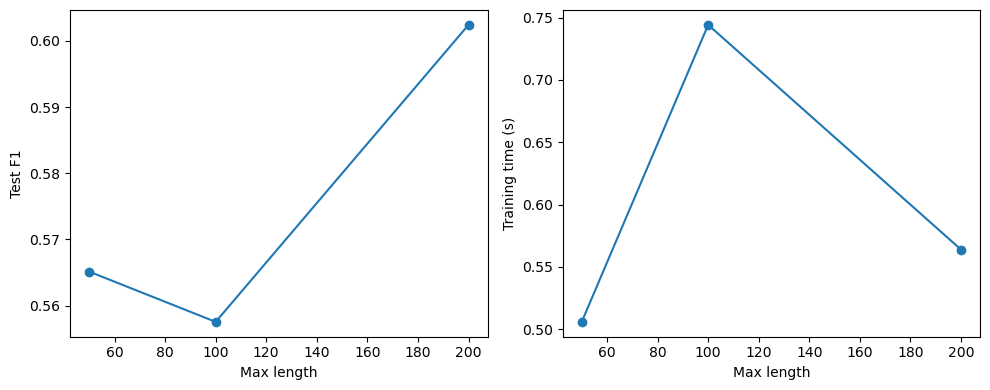

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(sequence.Max_length, sequence.F1, "o-")
axes[0].set_ylabel("Test F1")
axes[1].plot(sequence.Max_length, sequence.Training_time_s, "o-")
axes[1].set_ylabel("Training time (s)")
for ax in axes:
    ax.set_xlabel("Max length")
fig.tight_layout()
fig.savefig("sequence_tradeoff.png")
plt.show()


,Model,epoch,train_loss,validation_loss
0,RNN,1,0.6990,0.6931
1,RNN,2,0.6827,0.6937
2,RNN,3,0.6661,0.6962
3,LSTM,1,0.6943,0.6918
4,LSTM,2,0.6826,0.6861
5,LSTM,3,0.6546,0.6565
6,GRU,1,0.6949,0.6935
7,GRU,2,0.6788,0.6874
8,GRU,3,0.6479,0.6554


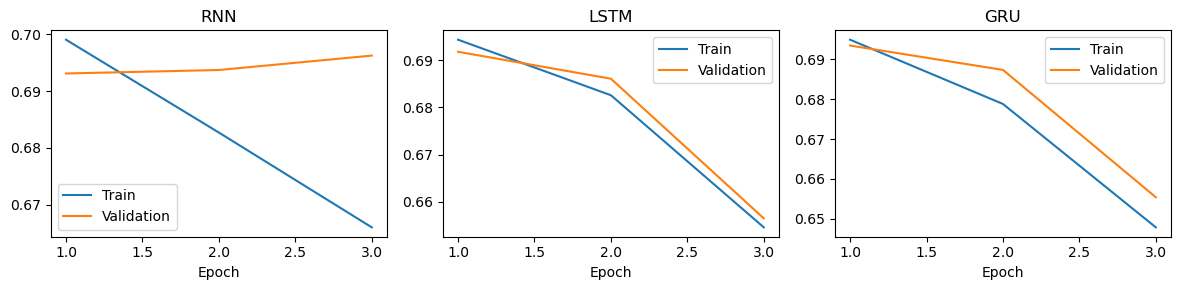

In [37]:
learning_curve_rows = []
for kind in ["RNN", "LSTM", "GRU"]:
    learning_curve_rows.extend({"Model": kind, **epoch} for epoch in histories[(kind, 100)])
learning_curves_df = pd.DataFrame(learning_curve_rows)
display(learning_curves_df.round(4))
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, kind in zip(axes, ["RNN", "LSTM", "GRU"]):
    history = pd.DataFrame(histories[(kind, 100)])
    ax.plot(history.epoch, history.train_loss, label="Train")
    ax.plot(history.epoch, history.validation_loss, label="Validation")
    ax.set_title(kind)
    ax.set_xlabel("Epoch")
    ax.legend()
fig.tight_layout()
fig.savefig("learning_curves.png")
plt.show()


In [38]:
# Kết quả lưu từ notebook cũ; không phải kết quả tính lại ở lần chạy hiện tại.
original_exp2_results = pd.DataFrame({
    "Max length": [50, 100, 200],
    "Tokens retained (%)": [21.55, 41.61, 68.70],
    "Training time (s)": [37.78, 41.97, 49.97],
    "Accuracy": [0.7129, 0.7063, 0.7335],
    "F1": [0.7159, 0.7130, 0.7395],
})
display(original_exp2_results)


,Max length,Tokens retained (%),Training time (s),Accuracy,F1
0,50,21.55,37.78,0.7129,0.7159
1,100,41.61,41.97,0.7063,0.7130
2,200,68.70,49.97,0.7335,0.7395


- Tăng max length có luôn cải thiện performance không?

Tăng max length không luôn cải thiện performance. Khi tăng từ 50 lên 100, tỷ lệ token được giữ lại tăng từ 21.55% lên 41.61%, nhưng Accuracy giảm từ 0.7129 xuống 0.7063 và F1 giảm từ 0.7159 xuống 0.7130.

Khi tăng lên 200, Accuracy và F1 đạt giá trị cao nhất trong ba cấu hình, lần lượt là 0.7335 và 0.7395. Tuy nhiên, thời gian huấn luyện cũng tăng từ 37.78 giây ở độ dài 50 lên 49.97 giây ở độ dài 200. Vì vậy, cần cân bằng giữa lượng ngữ cảnh được giữ lại, chất lượng dự đoán và chi phí tính toán. Trong phạm vi thí nghiệm này, max length 200 cho kết quả tốt nhất, nhưng chưa thể kết luận tăng tiếp sẽ tiếp tục cải thiện performance.

- Nếu max length quá nhỏ, loại thông tin nào có thể bị mất?

Do pipeline chỉ giữ các token đầu tiên, max length quá nhỏ có thể làm mất từ khóa sentiment, phần kết luận của review, thông tin phủ định hoặc đoạn thể hiện sự tương phản xuất hiện phía sau. Ví dụ, nếu câu “I expected the movie to be terrible, but it was actually wonderful” bị cắt trước phần “but”, nội dung còn lại có thể khiến mô hình dự đoán sai sentiment.

Với max length 50, chỉ 21.55% tổng số token được giữ lại, cho thấy lượng nội dung bị loại bỏ khá lớn. Tuy nhiên, tỷ lệ token bị mất không đồng nghĩa với tỷ lệ thông tin sentiment bị mất, vì không phải token nào cũng quan trọng như nhau đối với bài toán phân loại.

Có tồn tại trade-off giữa context và computational cost. Kết quả thực nghiệm cho thấy tồn tại trade-off rõ ràng giữa lượng thông tin ngữ cảnh được giữ lại và chi phí tính toán của mô hình GRU.

Khi tăng max_length từ 50 lên 200, tỷ lệ token được giữ lại tăng từ 21.55% lên 68.70%. Đồng thời, Validation F1 tăng từ 0.7627 lên 0.8553 và Validation Loss cuối cùng giảm từ 0.7638 xuống 0.4510. Điều này cho thấy việc giữ lại nhiều thông tin ngữ cảnh hơn giúp cải thiện hiệu suất phân loại sentiment trong thí nghiệm.

Tuy nhiên, thời gian huấn luyện cũng tăng từ 40.79 giây lên 58.73 giây, tương đương khoảng 44%. Mức sử dụng GPU memory được ghi nhận gần như không thay đổi đáng kể.

Ngoài ra, kết quả cho thấy dấu hiệu overfitting khi training loss tiếp tục giảm nhưng validation loss tăng ở những epoch cuối.

Kết luận: Trong phạm vi ba giá trị được khảo sát, max_length = 200 mang lại Validation F1 cao nhất nhưng cũng yêu cầu thời gian huấn luyện dài nhất. Do đó, việc lựa chọn max_length cần cân bằng giữa khả năng giữ lại ngữ cảnh, chất lượng dự đoán và chi phí tính toán. Không thể khẳng định rằng tiếp tục tăng max_length sẽ luôn cải thiện hiệu suất.

# Word order và Experiment 6 — Long-range dependency

In [39]:
def probabilities(model, texts, length=100):
    frame = pd.DataFrame({"review": texts, "label": 0})
    return evaluate(model, loader(frame, length))[1]


In [40]:
# Truncate trước shuffle: giữ nguyên tập token trong cả hai điều kiện.
original = [" ".join(tokenize(t)[:100]) for t in test.review]
rng = random.Random(SEED)
shuffled = []


In [41]:
for text in original:
    tokens = text.split()
    rng.shuffle(tokens)
    shuffled.append(" ".join(tokens))


In [42]:
order = []


In [43]:
for kind in ["TF-IDF + LR", "RNN", "LSTM", "GRU"]:
    if kind == "TF-IDF + LR":
        a = baseline.predict_proba(original)[:, 1]
        b = baseline.predict_proba(shuffled)[:, 1]
    else:
        a = probabilities(models[(kind, 100)], original)
        b = probabilities(models[(kind, 100)], shuffled)
    order.append(
        dict(
            Model=kind,
            Mean_probability_change=np.abs(a - b).mean(),
            Original_F1=metrics(test.label, a)["F1"],
            Shuffled_F1=metrics(test.label, b)["F1"],
        )
    )


In [44]:
order_df = pd.DataFrame(order)
display(order_df.round(4))
probes = []
filler = ("the movie has scenes with people in a town ".split() * 8)[:70]


,Model,Mean_probability_change,Original_F1,Shuffled_F1
0,TF-IDF + LR,0.0000,0.7764,0.7764
1,RNN,0.0555,0.5575,0.5336
2,LSTM,0.1063,0.4799,0.5000
3,GRU,0.1181,0.5573,0.5924



RNN thực sự sử dụng thông tin sequence mà TF-IDF không sử dụng có thể thấy rất rõ thông qua sự thay đổi kết quả dự đoán khi shuffle lại sequence. Cụ thể baseline sử dụng logistic regression không có sự thay đổi tức là thứ tự của sequence không làm thay đổi kết quả predict. Còn ở trường hợp của RNN thì có. 


In [45]:
for position, index in [("beginning", 0), ("middle", 35), ("end", 70)]:
    for word, label in [("excellent", 1), ("terrible", 0)]:
        tokens = filler.copy()
        tokens[index:index] = ["it", "was", word]
        text = " ".join(tokens)
        for kind in ["RNN", "LSTM", "GRU"]:
            prob = float(probabilities(models[(kind, 100)], [text])[0])
            probes.append(
                dict(
                    Model=kind,
                    Position=position,
                    Keyword=word,
                    True_label=label,
                    Positive_probability=prob,
                    Predicted=int(prob >= 0.5),
                    Text=text,
                )
            )


In [46]:
probes_df = pd.DataFrame(probes)
display(probes_df.drop(columns="Text").round(4))


,Model,Position,Keyword,True_label,Positive_probability,Predicted
0,RNN,beginning,excellent,1,0.4868,0
1,LSTM,beginning,excellent,1,0.2652,0
2,GRU,beginning,excellent,1,0.2342,0
3,RNN,beginning,terrible,0,0.4868,0
4,LSTM,beginning,terrible,0,0.2652,0
5,GRU,beginning,terrible,0,0.2342,0
6,RNN,middle,excellent,1,0.4868,0
7,LSTM,middle,excellent,1,0.2652,0
8,GRU,middle,excellent,1,0.2344,0
9,RNN,middle,terrible,0,0.4868,0


# Evaluation, error analysis và application

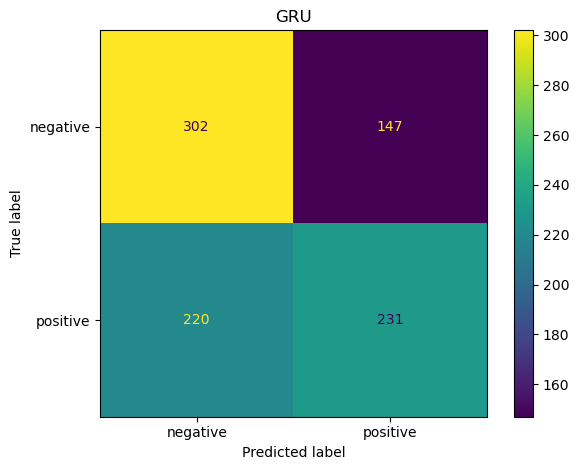

In [47]:
# Chọn LSTM/GRU bằng validation loss; test chỉ dùng để báo cáo.
best_kind = min(
    ["LSTM", "GRU"],
    key=lambda k: float(
        results[
            (results.Model == k) & (results.Max_length == 100)
        ].Validation_loss.iloc[0]
    ),
)
best = models[(best_kind, 100)]
_, p, y = evaluate(best, loader(test, 100))
pred = p >= 0.5
cm_display = ConfusionMatrixDisplay.from_predictions(
    y, pred, display_labels=["negative", "positive"]
)
cm_display.ax_.set_title(best_kind)
cm_display.figure_.tight_layout()
cm_display.figure_.savefig("confusion_matrix.png")
plt.show()


In [48]:
analysis = test[["review", "label"]].reset_index(drop=True).copy()


In [49]:
analysis["predicted"] = pred.astype(int)
analysis["positive_probability"] = p
analysis["tokens"] = analysis.review.map(lambda t: len(tokenize(t)))
analysis["truncated"] = analysis.tokens > 100
analysis["unk_ratio"] = analysis.review.map(
    lambda t: sum(w not in vocab for w in tokenize(t)) / max(1, len(tokenize(t)))
)


In [50]:
correct_examples = analysis[analysis.label == analysis.predicted].head(3)
incorrect_examples = analysis[analysis.label != analysis.predicted].head(3)
display(correct_examples)
display(incorrect_examples)


,review,label,predicted,positive_probability,tokens,truncated,unk_ratio
0,So boring you'll fall asleep after the 20 firs...,0,0,0.319671,107,True,0.037383
1,end of the world looks like a good movie on th...,0,0,0.295899,219,True,0.059361
2,"After the success of ""Muppet Babies"" Warner Br...",1,1,0.637059,499,True,0.096192


,review,label,predicted,positive_probability,tokens,truncated,unk_ratio
3,"Once a year in America, Saturday morning would...",1,0,0.243481,355,True,0.030986
4,Everything you do in this world should make at...,0,1,0.705686,110,True,0.090909
5,"""Jaded"" should not be considered as en erotic ...",1,0,0.494374,259,True,0.019305


In [51]:
examples = {
    "short": "I really enjoyed this movie.",
    "long": "The movie follows a family through a series of events. " * 25
    + "Overall I loved the ending and the performances.",
    "negation": "I did not enjoy this movie. It was not good.",
    "contrast": "I thought the movie would be terrible, but it was surprisingly good.",
}
app = []


In [52]:
for case, text in examples.items():
    prob = float(probabilities(best, [text])[0])
    app.append(
        dict(
            Case=case,
            Text=text,
            Sentiment="Positive" if prob >= 0.5 else "Negative",
            Positive_probability=prob,
            Truncated=len(tokenize(text)) > 100,
        )
    )


In [53]:
application_df = pd.DataFrame(app)
display(application_df.round(4))
print("Selected model:", best_kind)


,Case,Text,Sentiment,Positive_probability,Truncated
0,short,I really enjoyed this movie.,Positive,0.5357,False
1,long,The movie follows a family through a series of...,Positive,0.5747,True
2,negation,I did not enjoy this movie. It was not good.,Positive,0.5048,False
3,contrast,"I thought the movie would be terrible, but it ...",Negative,0.2547,False


Selected model: GRU


## Word order — kết quả đã chạy

| Model | Mean_probability_change | Original_F1 | Shuffled_F1 |
| --- | --- | --- | --- |
| TF-IDF + LR | 0.0 | 0.7764449291166848 | 0.7764449291166848 |
| RNN | 0.0554847542113728 | 0.5575396825396826 | 0.5335929892891919 |
| LSTM | 0.10631518676877022 | 0.47989276139410186 | 0.504225352112676 |
| GRU | 0.11802104857232835 | 0.5551515151515152 | 0.5914110429447853 |


## Long-range dependency — kết quả đã chạy

| Model | Position | Keyword | True_label | Positive_probability | Predicted |
| --- | --- | --- | --- | --- | --- |
| RNN | beginning | excellent | 1 | 0.4868585467338562 | 0 |
| LSTM | beginning | excellent | 1 | 0.2652447819709778 | 0 |
| GRU | beginning | excellent | 1 | 0.23420001566410065 | 0 |
| RNN | beginning | terrible | 0 | 0.4868585467338562 | 0 |
| LSTM | beginning | terrible | 0 | 0.2652445137500763 | 0 |
| GRU | beginning | terrible | 0 | 0.23417742550373077 | 0 |
| RNN | middle | excellent | 1 | 0.4868585467338562 | 0 |
| LSTM | middle | excellent | 1 | 0.26529258489608765 | 0 |
| GRU | middle | excellent | 1 | 0.2343984842300415 | 0 |
| RNN | middle | terrible | 0 | 0.4868585467338562 | 0 |
| LSTM | middle | terrible | 0 | 0.2652435004711151 | 0 |
| GRU | middle | terrible | 0 | 0.23413203656673431 | 0 |
| RNN | end | excellent | 1 | 0.5313984155654907 | 1 |
| LSTM | end | excellent | 1 | 0.38493314385414124 | 0 |
| GRU | end | excellent | 1 | 0.3396892845630646 | 0 |
| RNN | end | terrible | 0 | 0.45398247241973877 | 0 |
| LSTM | end | terrible | 0 | 0.2797205448150635 | 0 |
| GRU | end | terrible | 0 | 0.25234124064445496 | 0 |


## Application — kết quả đã chạy

| Case | Sentiment | Positive_probability | Truncated |
| --- | --- | --- | --- |
| short | Positive | 0.5354300141334534 | False |
| long | Positive | 0.5721408724784851 | True |
| negation | Positive | 0.5041691660881042 | False |
| contrast | Negative | 0.25439485907554626 | False |
